In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

(<Axes: >, <matplotlib.image.AxesImage at 0x716bef1134d0>)

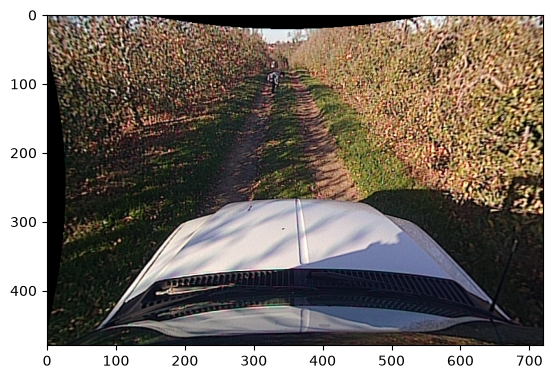

In [22]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
BASE_DIR='/media/dpaulino/31c12798-f2e4-45f8-9614-3dd2fec82907/agriImages/content/nrec/selected/images/train/'

image1=BASE_DIR+'Image_0_0_1447440969.257.png'
#image1=BASE_DIR+'Image_0_0_1447083652.066.png'
#image1=BASE_DIR+'Image_0_0_1447083654.066.png'
#image1=BASE_DIR+'Image_0_0_1447086544.902.png'
image1=BASE_DIR+'Image_0_0_1447086547.169.png'
image1=BASE_DIR+'Image_0_0_1447689038.248.png'
#image1=BASE_DIR+'Image_0_0_1447689939.060.png'
image1=BASE_DIR+'Image_0_0_1447702858.930.png'

img = cv2.imread(image1).astype("uint8")
gray_image = cv2.imread(image1, cv2.IMREAD_GRAYSCALE)

rgb_image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gray_image_g = cv2.GaussianBlur(gray_image,(43,43),0)
#ret, thresh_img = cv2.threshold(gray_image_g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

ret, thresh_img = cv2.threshold(gray_image_g, 80, 255, cv2.THRESH_BINARY)

plt.subplot(1,1,1),plt.imshow(rgb_image)





In [23]:
gray_image

array([[125, 124, 119, ..., 138,  89,  60],
       [141, 140, 128, ..., 171, 118,  94],
       [142, 152, 142, ..., 148,  41,  88],
       ...,
       [ 30,  24,  23, ...,  20,  26,  29],
       [ 30,  18,   0, ...,  15,  15,  17],
       [ 28,  29,  25, ...,  43,  26,  22]], shape=(480, 720), dtype=uint8)

0.0<>1.0


array([[0.52991548, 0.53634172, 0.54275535, ..., 0.34628632, 0.35107445,
        0.35596408],
       [0.52348477, 0.52991101, 0.53632472, ..., 0.34324473, 0.34799784,
        0.35285473],
       [0.5170667 , 0.52349286, 0.52990657, ..., 0.34021336, 0.34493153,
        0.34975574],
       ...,
       [0.37943687, 0.37412837, 0.3688311 , ..., 0.62396935, 0.62328758,
        0.62244773],
       [0.37870894, 0.37342865, 0.36815964, ..., 0.62352603, 0.62285123,
        0.6220197 ],
       [0.37790315, 0.37265334, 0.36741485, ..., 0.62304158, 0.62237427,
        0.62155168]], shape=(480, 720))

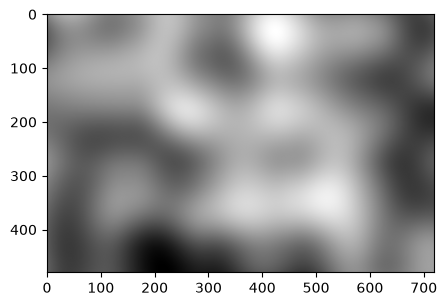

In [24]:
import vnoise
import numpy as np
import matplotlib.pyplot  as plt
import cv2


shape=(480,720)
scale=300
octaves=2
persistence=1
lacunarity = 2

noise = vnoise.Noise()
y=np.linspace(0,480/scale,480)
x=np.linspace(0,720/scale,720)

image = noise.noise2(y,x,grid_mode=True,octaves=octaves,persistence=persistence,lacunarity=lacunarity,base=42)

image=(image-np.min(image))/(np.max(image)-np.min(image))

image_gaus = cv2.GaussianBlur(image,(1,1),0)

fig = plt.figure(figsize=(5,5))
plt.imshow(image_gaus,'gray')
print(f'{np.min(image)}<>{np.max(image)}')
image

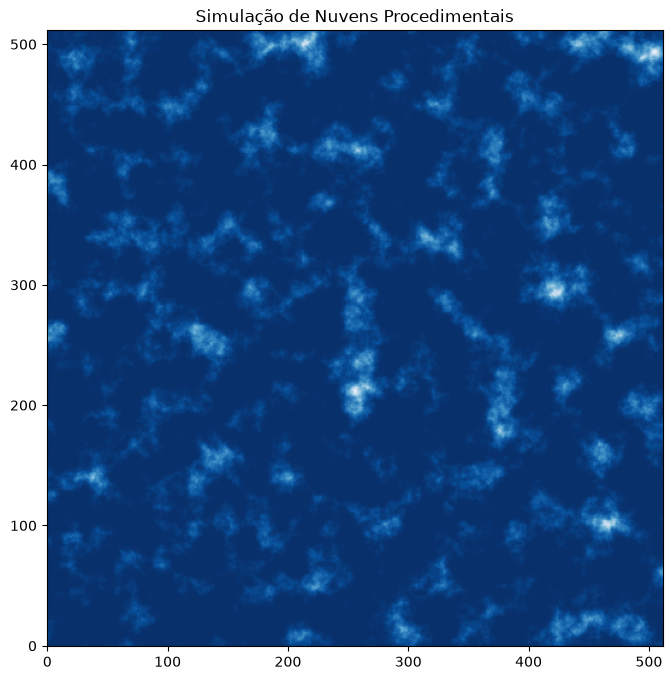

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import vnoise

# 1. Configuração da Grelha/Resolução
resolucao = 512
escala = 40.0  # Controla o tamanho das nuvens (menor = nuvens maiores)

# Criar vetores 1D lineares para o vnoise em grid_mode
x = np.linspace(0, resolucao / escala, resolucao)
y = np.linspace(0, resolucao / escala, resolucao)

# 2. Inicializar o vnoise com uma semente
vn = vnoise.Noise(seed=1234)

# 3. Gerar o Ruído Perlin Base (focado em detalhes de nuvem)
# grid_mode=True cria a matriz 2D diretamente combinando os vetores x e y
ruido_base = vn.noise2(
    x,
    y,
    octaves=6,  # Mais oitavas adicionam os detalhes "esfarrapados" das nuvens
    persistence=0.55,  # Controla o peso dos detalhes nas bordas
    lacunarity=2.1,
    grid_mode=True,
)

# 4. Normalizar o ruído para o intervalo [0, 1]
ruido_norm = (ruido_base - ruido_base.min()) / (
    ruido_base.max() - ruido_base.min()
)

# 5. Processamento para Efeito de Nuvem (O Segredo)
limiar_ceu = 0.4  # Valores abaixo disto viram céu limpo (0)
densidade = 2.5  # Expoente: valores altos tornam o centro da nuvem mais denso

# Remove o "fundo" para criar clareiras no céu
nuvens = np.maximum(0, ruido_norm - limiar_ceu)
# Renormaliza após o corte
nuvens = nuvens / (1.0 - limiar_ceu)
# Aplica a curva de densidade (exponenciação)
nuvens = np.power(nuvens, densidade)

# 6. Visualização Gráfica
plt.figure(figsize=(8, 8))
# Usamos um mapa de cores personalizado (Céu Azul -> Nuvens Brancas)
plt.imshow(nuvens, cmap="Blues_r", origin="lower")

plt.title("Simulação de Nuvens Procedimentais")
plt.show()

(<Axes: >, <matplotlib.image.AxesImage at 0x7042dec52c10>)

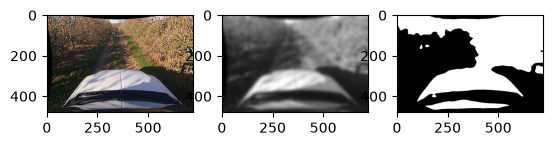

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
BASE_DIR='/media/dpaulino/31c12798-f2e4-45f8-9614-3dd2fec82907/agriImages/content/nrec/selected/images/train/'

image1=BASE_DIR+'Image_0_0_1447440969.257.png'
#image1=BASE_DIR+'Image_0_0_1447083652.066.png'
#image1=BASE_DIR+'Image_0_0_1447083654.066.png'
#image1=BASE_DIR+'Image_0_0_1447086544.902.png'
image1=BASE_DIR+'Image_0_0_1447086547.169.png'
#image1=BASE_DIR+'Image_0_0_1447689038.248.png'
#image1=BASE_DIR+'Image_0_0_1447689939.060.png'
image1=BASE_DIR+'Image_0_0_1447702858.930.png'

img = cv2.imread(image1).astype("uint8")
gray_image = cv2.imread(image1, cv2.IMREAD_GRAYSCALE)
# 2. Converte o espaço de cor de BGR para RGB
rgb_image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gray_image_g = cv2.GaussianBlur(gray_image,(43,43),0)
#ret, thresh_img = cv2.threshold(gray_image_g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

ret, thresh_img = cv2.threshold(gray_image_g, 80, 255, cv2.THRESH_BINARY)

plt.subplot(1,3,1),plt.imshow(rgb_image)
plt.subplot(1,3,2),plt.imshow(gray_image_g,'gray')
plt.subplot(1,3,3),plt.imshow(thresh_img,'gray')


/home/dpaulino/anaconda3/envs/project/lib/python3.13/site-packages/vnoise/__init__.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


INFO - creating occlusion instance of smoke with factor 0.2


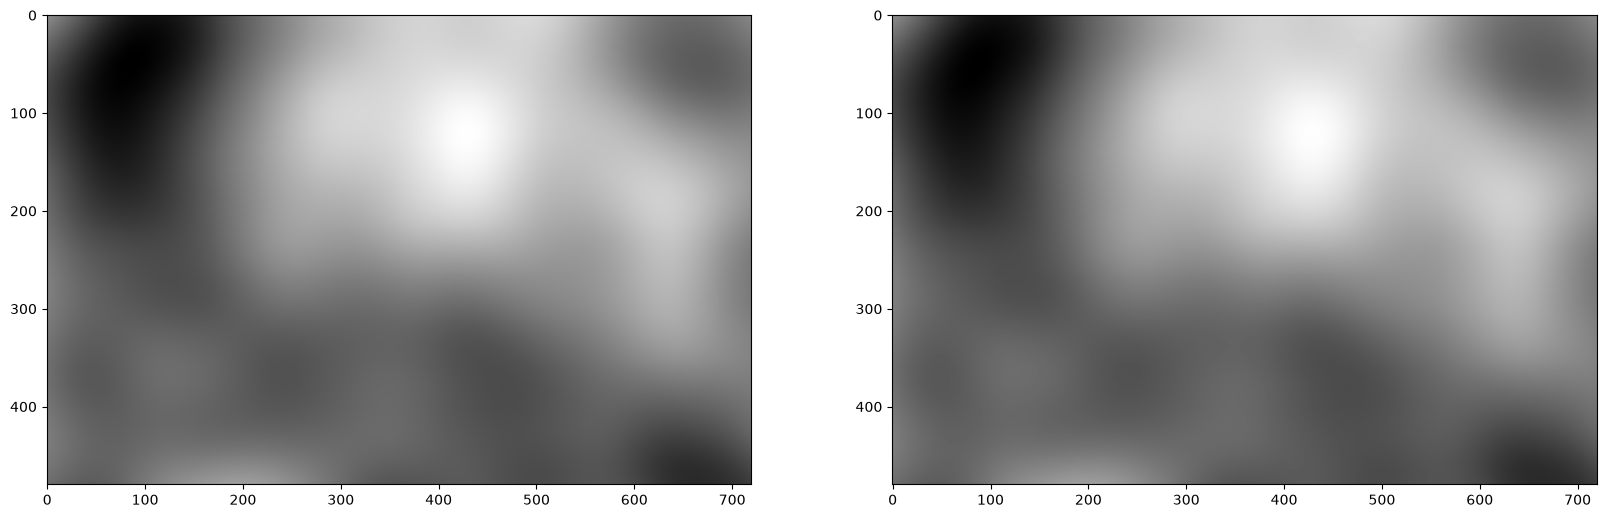

np.float64(1.0)

In [2]:
from nrec_utils.occlusions.smoke_occlusion import Smoke

smoke_occ=Smoke(0.2)
smoke2d = smoke_occ.generate_random_smoke2d(rgb_image,seed=150)

smoke3d = cv2.merge([smoke2d,smoke2d,smoke2d])

_,smoke_mask = cv2.threshold(smoke2d,100,255,cv2.THRESH_BINARY)

fig = plt.figure(figsize=(20, 10))
plt.subplot(1,2,1)
plt.imshow(smoke3d,'gray')
plt.subplot(1,2,2)
plt.imshow(smoke2d,'gray')
plt.show()
np.max(smoke2d/255.0)



INFO - creating occlusion instance of smoke with factor 0.2
INFO - creating occlusion instance of smoke with factor 0.1
INFO - creating occlusion instance of smoke with factor 0.2
INFO - creating occlusion instance of smoke with factor 0.3


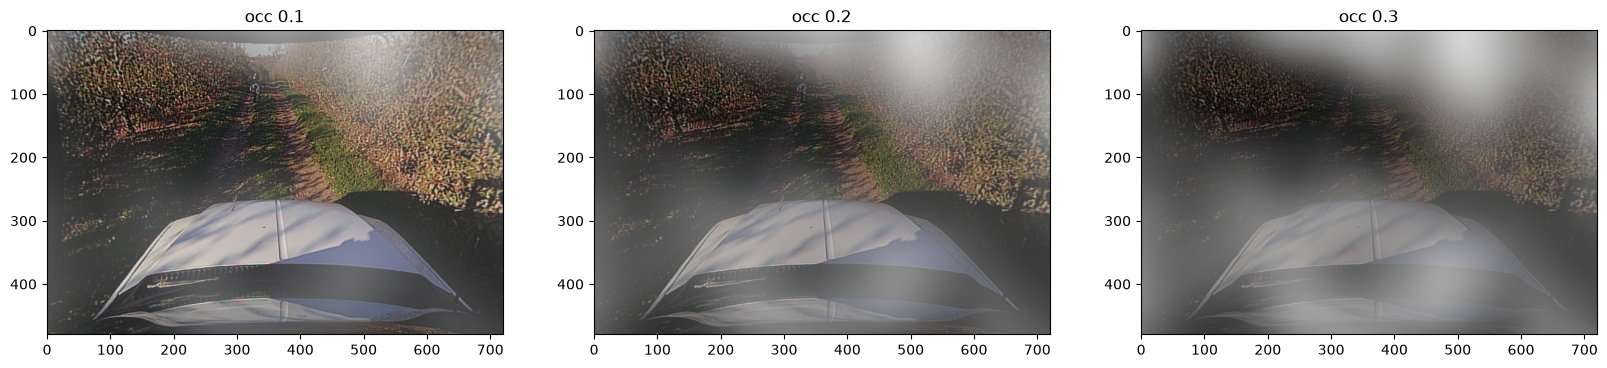

In [3]:
from nrec_utils.occlusions.smoke_occlusion import fake_depth_map,Smoke
smoke_occ=Smoke(0.2)
occ_img = smoke_occ.generate_occluded_image(image=rgb_image, bboxs=[],seed=150)

fig = plt.figure(figsize=(20, 10))
#plt.subplot(1,2,1)
#plt.imshow(occ_img)
#plt.subplot(1,2,2)
#plt.imshow(rgb_image,'gray')
#plt.show()

for i,occ_factor in enumerate([0.1,0.2,0.3]):
    smoke_occ=Smoke(occ_factor)
    occ_img = smoke_occ.generate_occluded_image(image=rgb_image, bboxs=[],seed=152)
    plt.subplot(1,3,(i+1))
    plt.title(f'occ {occ_factor}')
    plt.imshow(occ_img)

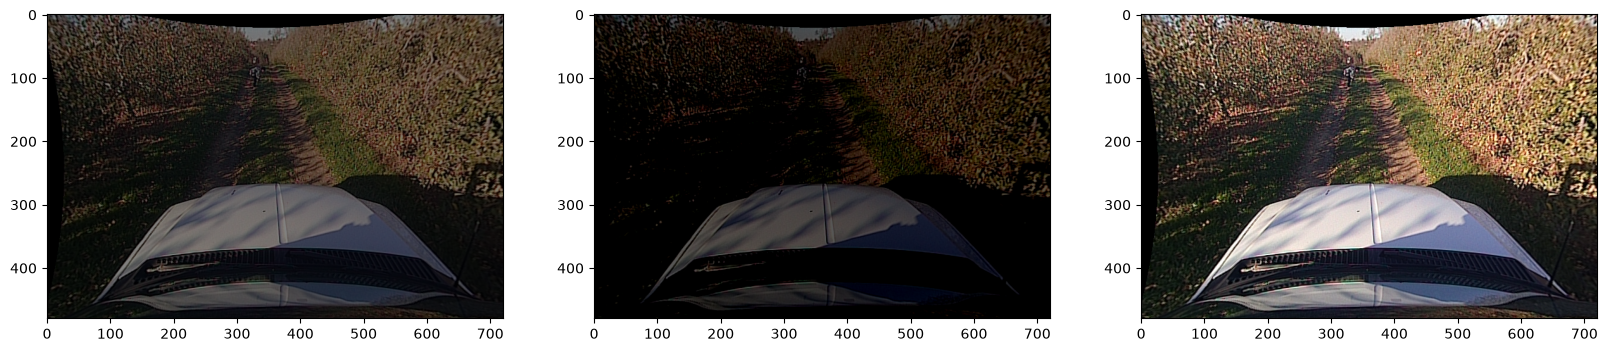

In [36]:
from nrec_utils.occlusions.smoke_occlusion import adjust_brightness_bisection,adjust_brightness_simple

img_dark_bisection=adjust_brightness_bisection(rgb_image,0.5,10)
img_dark_simple=adjust_brightness_simple(rgb_image,0.5)
fig = plt.figure(figsize=(20, 10))

plt.subplot(1,3,1)
plt.imshow(img_dark_bisection)
plt.subplot(1,3,2)
plt.imshow(img_dark_simple)
plt.subplot(1,3,3)
plt.imshow(rgb_image)
plt.show()

INFO - creating occlusion instance of smoke with factor 0.2


array([[2.94415798e-05, 2.94415798e-05, 2.94415798e-05, ...,
        2.94415798e-05, 2.94415798e-05, 2.94415798e-05],
       [2.94650151e-05, 2.94650151e-05, 2.94650151e-05, ...,
        2.94650151e-05, 2.94650151e-05, 2.94650151e-05],
       [2.95119550e-05, 2.95119550e-05, 2.95119550e-05, ...,
        2.95119550e-05, 2.95119550e-05, 2.95119550e-05],
       ...,
       [8.99401832e-01, 8.99401832e-01, 8.99401832e-01, ...,
        8.99401832e-01, 8.99401832e-01, 8.99401832e-01],
       [8.99416166e-01, 8.99416166e-01, 8.99416166e-01, ...,
        8.99416166e-01, 8.99416166e-01, 8.99416166e-01],
       [8.99423335e-01, 8.99423335e-01, 8.99423335e-01, ...,
        8.99423335e-01, 8.99423335e-01, 8.99423335e-01]], shape=(480, 720))

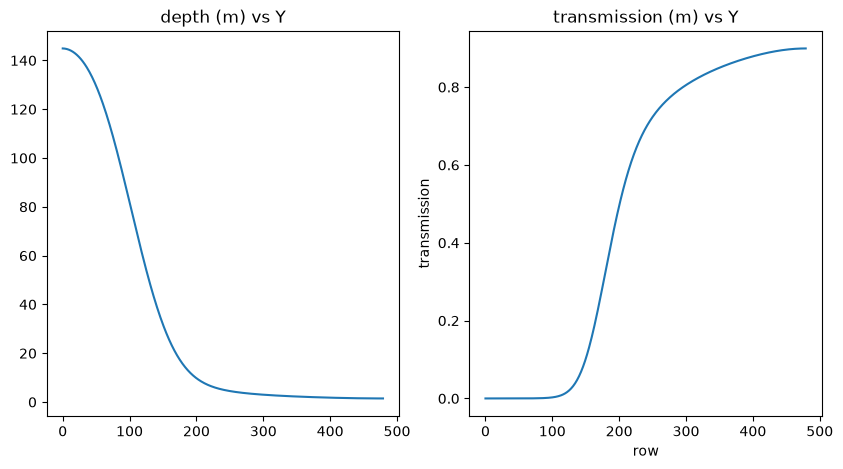

In [10]:
# transmission curve
from nrec_utils.occlusions.smoke_occlusion import fake_depth_map,Smoke

depth = fake_depth_map(rgb_image,z_max=150,sigma_frac=0.1)
depth[:,1]
y = range(0,len(depth[:,1]))
fig = plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.plot(y,depth[:,1])
plt.title('depth (m) vs Y')

smoke = Smoke(0.2)
beta=0.3*0.06*4
transmission = smoke.calculate_transmission_gaussian(beta=beta,depth=depth,density=1.0)
transmission[:,1]
plt.subplot(1,2,2)
plt.plot(y,transmission[:,1])
plt.xlabel('row')
plt.ylabel('transmission')
plt.title('transmission (m) vs Y')
transmission